# Window visualiser

Plot a test patient's 10 s windows next to the spectrogram the model received, with the
true label, prediction and P(AF). Green = correct, red = misclassified.

- `dataset`: `'afdb'`, `'icentia_100'` or `'icentia_zeroshot'` (see `DATASETS` in `infrastructure/visual.py`)
- `fold`: the fold whose **test** set contains the patient (for `icentia_zeroshot`, it picks the AFDB checkpoint)
- `run`: optional, a different results folder (e.g. `run='bgm_afdb_1_authcopy'`)
- Icentia11k needs the Seagate mounted.

In [7]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from infrastructure.visual import load_patient, patient_summary, plot_windows

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Choose a patient

In [11]:
dataset, fold, patient = 'icentia_100', 2, 'p00060'
patient_summary(dataset, fold, patient)

,Predicted N,Predicted AF,Total,Correct,Accuracy
True N,0,0,0,0,NaN
True AF,10465,814,11279,814,0.0722
Total,10465,814,11279,814,0.0722


## Misclassified windows

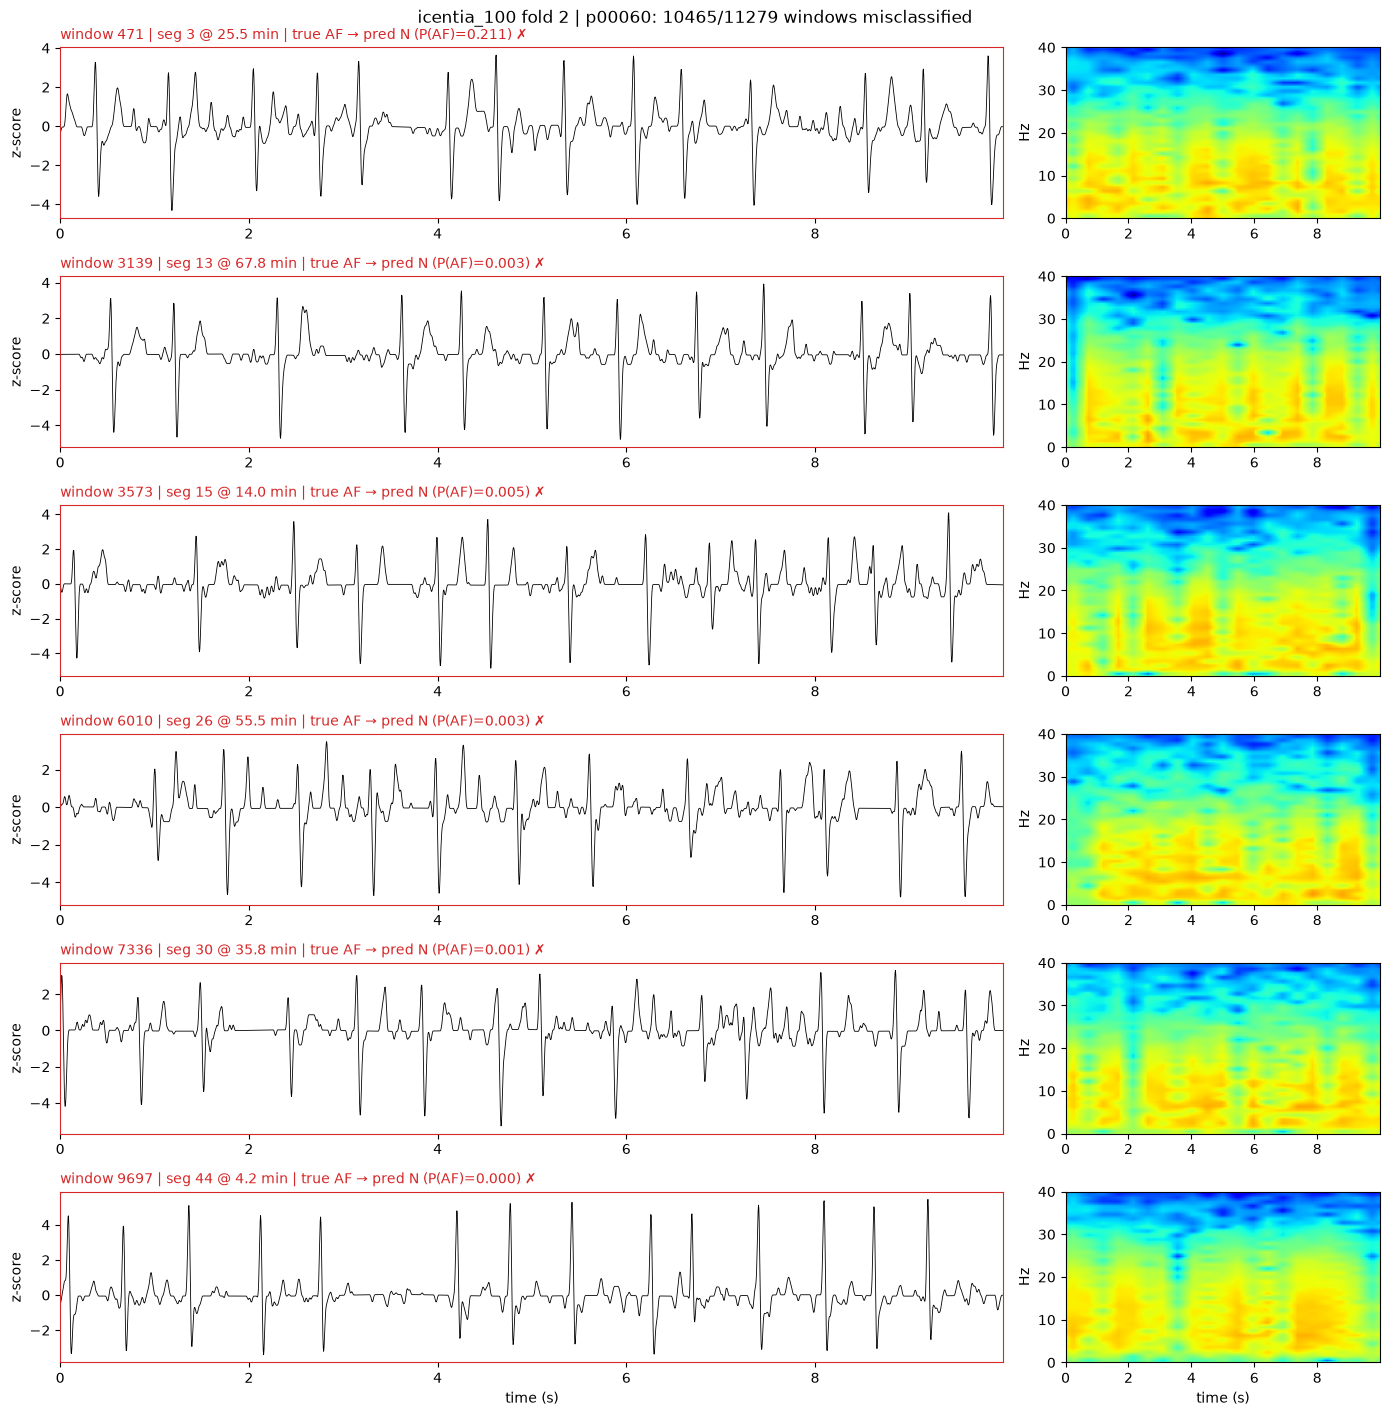

,true,pred,p_AF,correct,seg_idx,start_sample
471,AF,N,0.210879,False,3,382500
3139,AF,N,0.003361,False,13,1017500
3573,AF,N,0.005363,False,15,210000
6010,AF,N,0.003296,False,26,832500
7336,AF,N,0.001358,False,30,537500
9697,AF,N,0.000107,False,44,62500


In [12]:
plot_windows(dataset, fold, patient, show='incorrect', n=6)

## Correctly classified windows (for comparison)

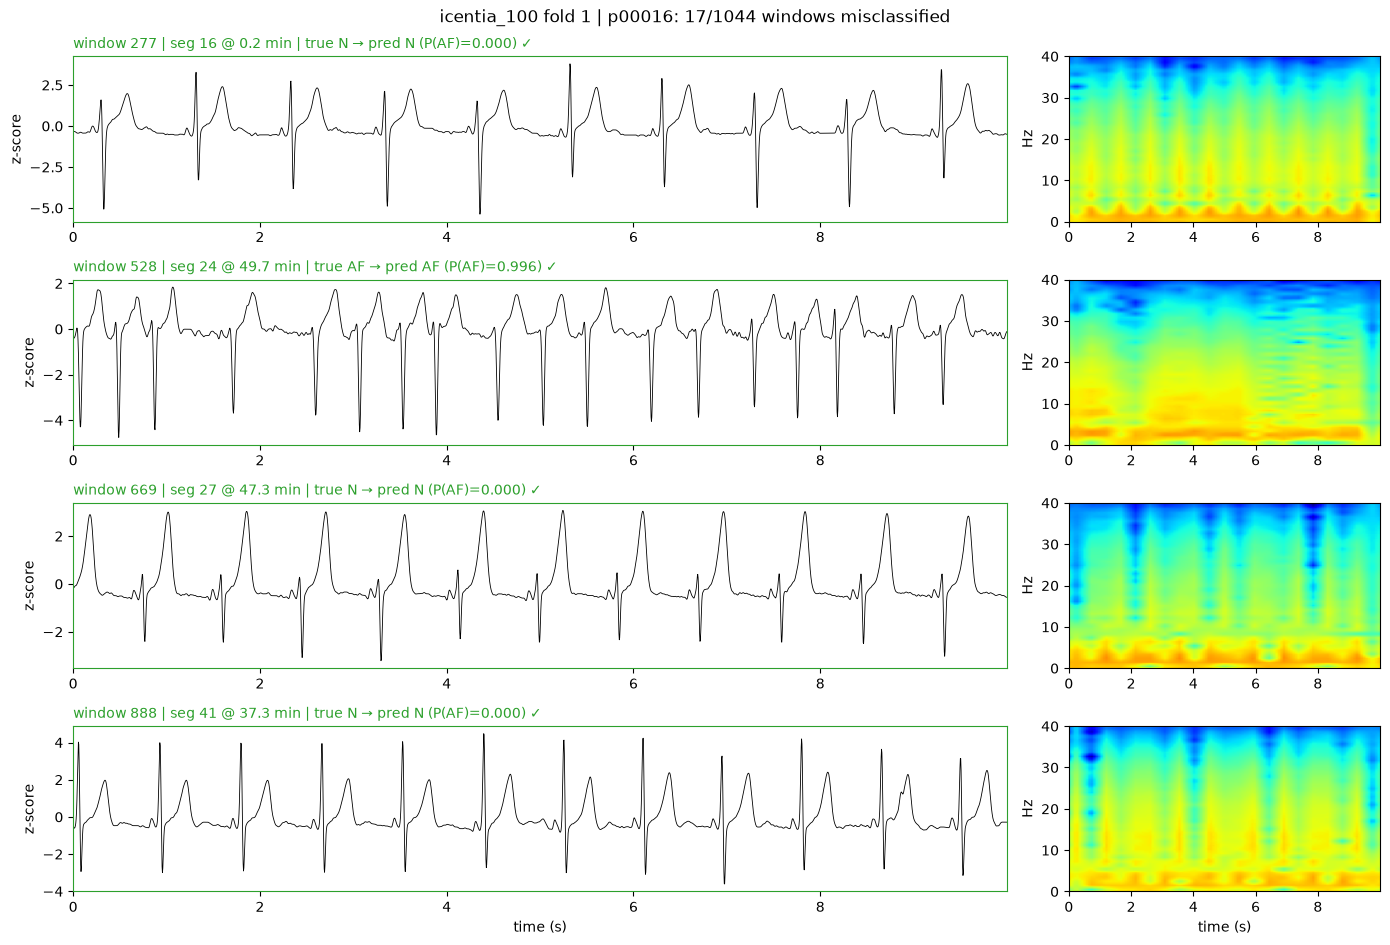

,true,pred,p_AF,correct,seg_idx,start_sample
277,N,N,4.693267e-08,True,16,2500
528,AF,AF,9.959008e-01,True,24,745000
669,N,N,3.815363e-07,True,27,710000
888,N,N,1.037308e-07,True,41,560000


In [4]:
plot_windows(dataset, fold, patient, show='correct', n=4)

## Specific windows
Use the row numbers from `load_patient`'s table, e.g. the least confident ones.

In [5]:
segments, table = load_patient(dataset, fold, patient)
table.sort_values('p_AF').query('true == "AF"').head(10)

,true,pred,p_AF,correct,seg_idx,start_sample
617,AF,N,0.002287,False,24,1015000
591,AF,N,0.002542,False,24,920000
589,AF,N,0.003554,False,24,912500
622,AF,N,0.036264,False,24,1027500
512,AF,N,0.041541,False,24,705000
619,AF,N,0.072688,False,24,1020000
588,AF,N,0.090650,False,24,910000
529,AF,N,0.210422,False,24,747500
515,AF,N,0.244682,False,24,712500
613,AF,N,0.257646,False,24,1000000


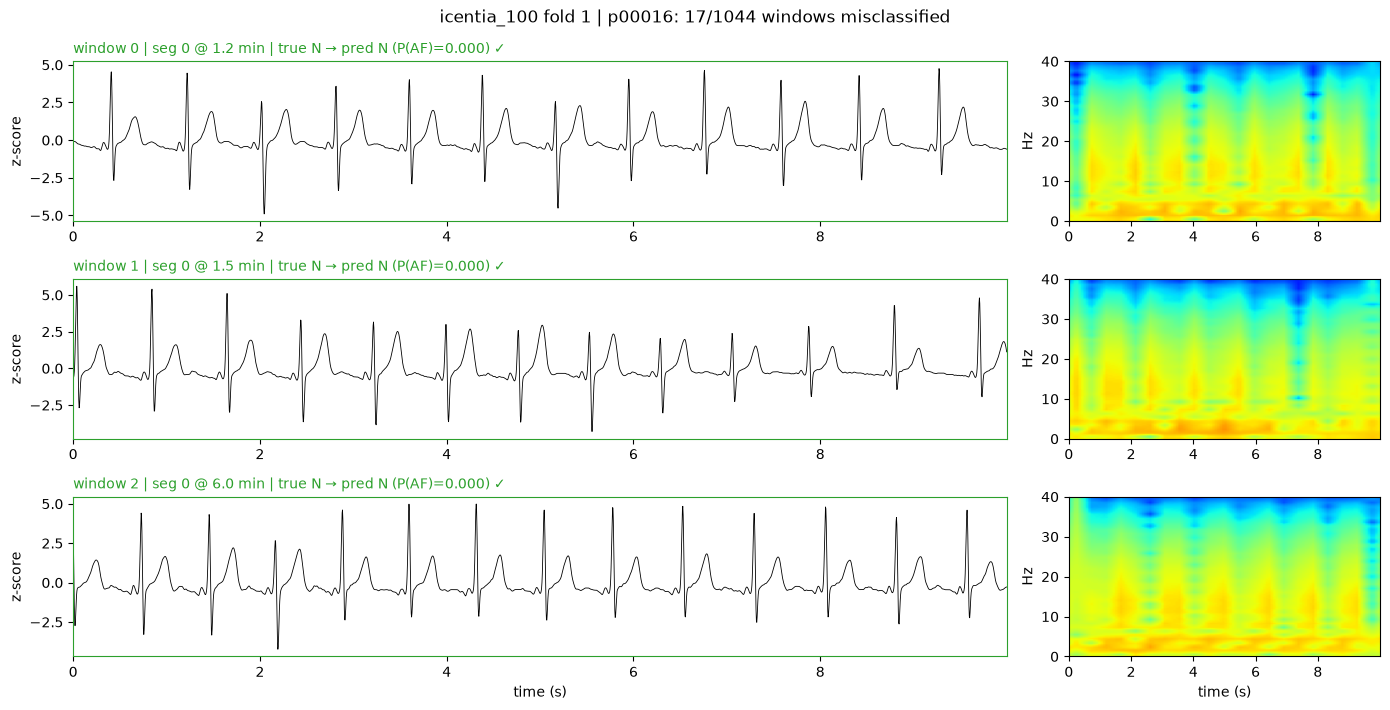

,true,pred,p_AF,correct,seg_idx,start_sample
0,N,N,4.355498e-08,True,0,17500
1,N,N,6.170489e-08,True,0,22500
2,N,N,1.465682e-07,True,0,90000


In [6]:
plot_windows(dataset, fold, patient, windows=[0, 1, 2])

# Grad-CAM

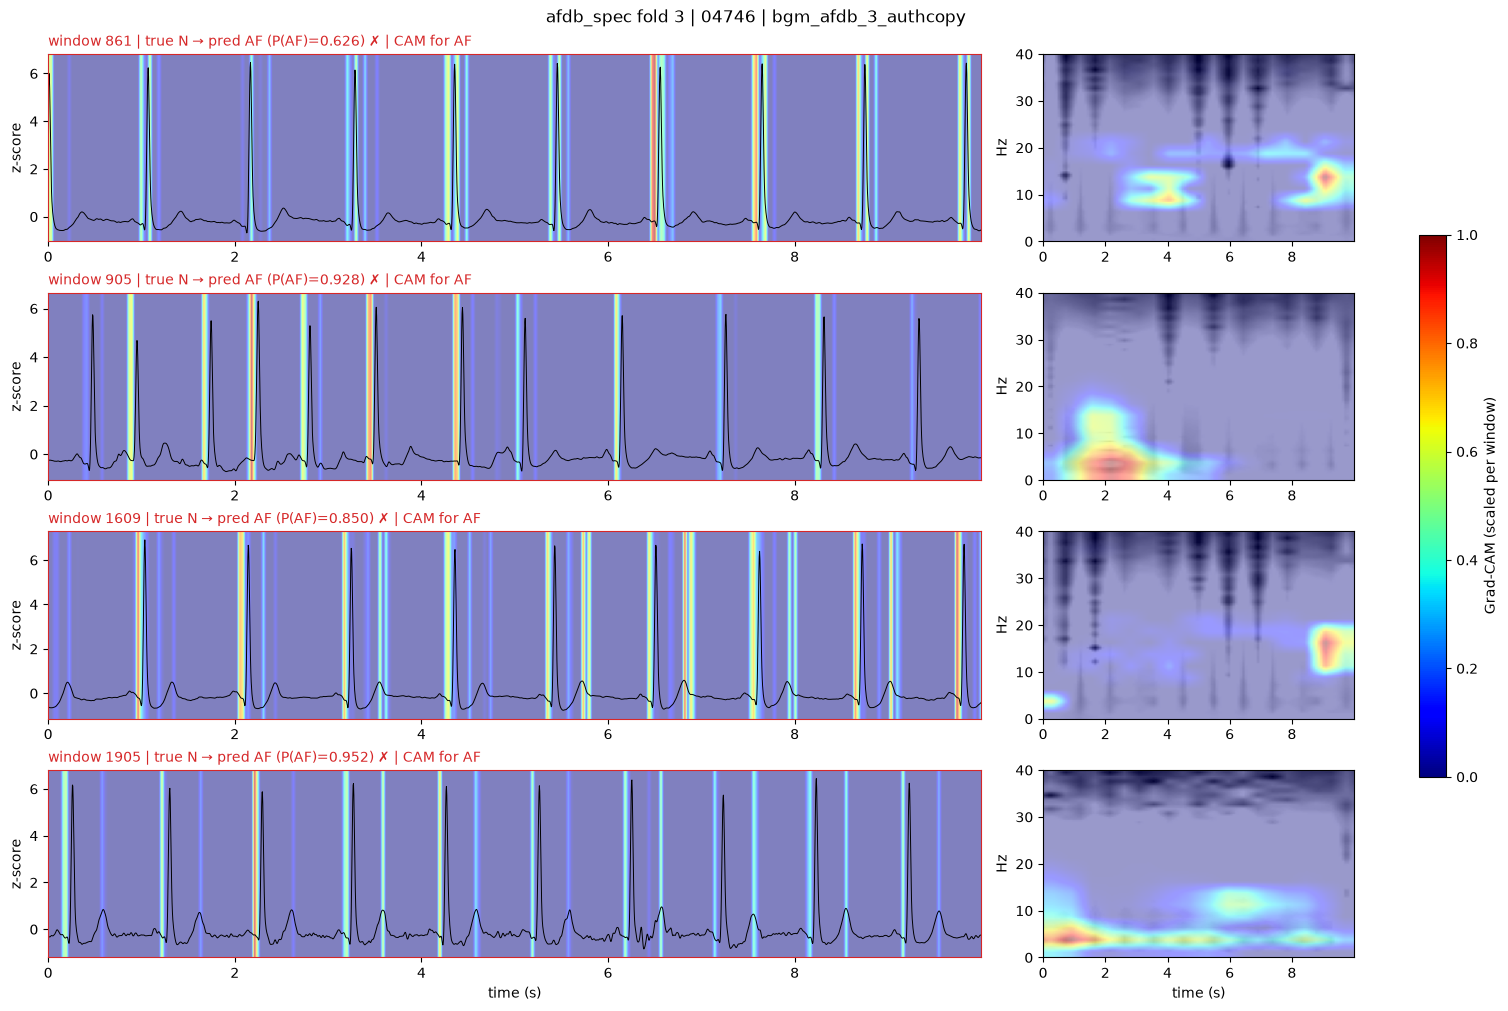

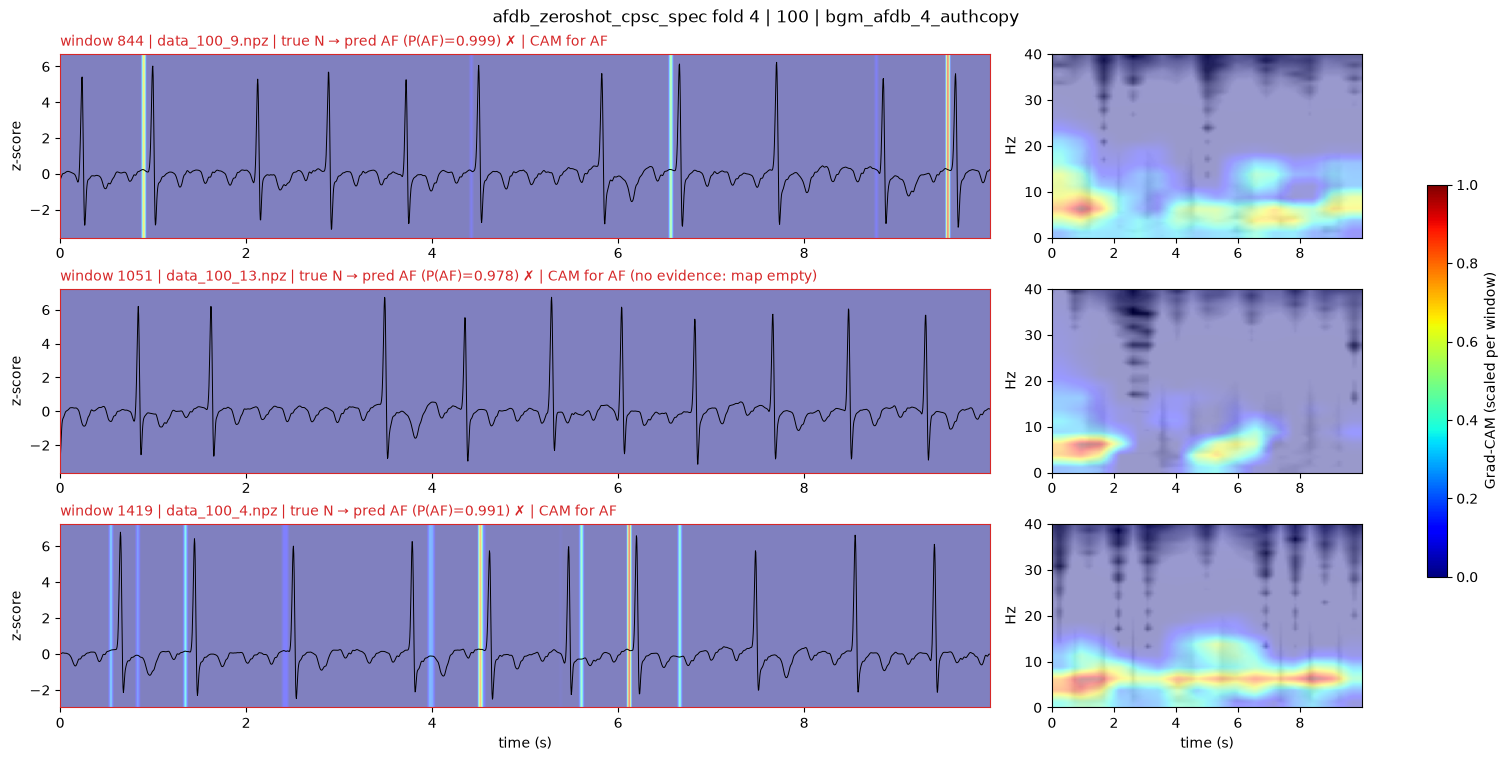

ValueError: 04015 is not in the test set of afdb_acc fold 1

In [1]:
from infrastructure.visual import plot_gradcam, gradcam_windows

plot_gradcam('afdb_spec', 3, '04746', show='incorrect', n=4)               # explain the model's prediction, as in the paper
plot_gradcam('afdb_zeroshot_cpsc_spec', 4, '100', n=3, target='AF')        # CPSC case 100, "what looks like AF?"
rows, maps = gradcam_windows('afdb_acc', 1, '04015', windows=[10, 11])     # raw maps for your own analysis
